# 1 · Count the compute

The top of the leaderboard (BuzinD, 96.6%) is a small residual network trained for 28
epochs, which answers by looking at each test image in 8 orientations. Our goal for
demo 2: **the same accuracy (96.3% or more) for at most a fifth of its compute**, both
for training and for labelling a test image.

Before we try anything, we work out where the compute goes. Compute is not a mystery
you measure after the fact: for a convolutional network you can count it with a
pencil. Once you can count it, you know which knobs make a model cheaper, by how much,
and what each one will have to give up. That turns "make it cheaper" into a short list
of experiments, which notebook 2 runs.

This notebook trains nothing: it runs in a few seconds on any laptop.

In [1]:
import lab
import matplotlib.pyplot as plt
import model
import torch
from model import Config
from torch.utils.flop_counter import FlopCounterMode

leader = Config()  # model.py's settings start as the leader's: we change them in notebook 2
print(leader)

Config(stem='conv', stem_stride=2, stem_pool=True, block='basic', widths=(24, 48, 96), depths=(1, 1, 1), expand=4, zero_init=False, epochs=28, batch_size=128, lr=0.006, weight_decay=0.01, pct_start=0.2, label_smoothing=0.0, ema=0.0, augment=True, low_res=0.0, tta=8, valid_images=0, device='cpu', watch=None)


`model.py` holds one family of networks with many settings, and the training loop. Its
defaults start as an exact copy of the leader (BuzinD's `model.py`): a 3x3 convolution
that moves 2 pixels at a time, a max pool, then three residual blocks of 24, 48 and 96
channels, each stage at half the size of the one before. Every later idea is a setting
we can turn on in a notebook without touching the defaults.

## 1 · What is a FLOP?

One FLOP is one multiply or one add of two decimal numbers. A convolution that turns
`c_in` channels into `c_out` channels with a `k x k` window does, for every output pixel
and every output channel, `k x k x c_in` multiplies and as many adds:

$$\text{FLOPs} = 2 \times k^2 \times c_\text{in} \times c_\text{out} \times H_\text{out} \times W_\text{out}$$

The leader's first layer: 3x3 windows, 3 colors in, 24 channels out, and stride 2 makes
its output 32x32 pixels.

In [2]:
by_hand = 2 * 3 * 3 * 3 * 24 * 32 * 32
counter = FlopCounterMode(display=False)
with counter:
    model.make_model(leader)[0](torch.rand(1, 3, 64, 64))  # only the first layer
print(f"by hand: {by_hand:,}   PyTorch's counter: {counter.get_total_flops():,}")

by hand: 1,327,104   PyTorch's counter: 1,327,104


The same number. The scorer uses this counter (`src/eurosat/flops.py`), so what we can
count by hand is exactly what the leaderboard shows. Everything that is not a
convolution or a matrix multiply (ReLU, batch norm, pooling, the optimizer) is cheap
next to them, and the leaderboard does not count it.

## 2 · Where does the leader's compute go?

We count each layer of the network, for one 64x64 image.

stem: 3x3 conv, 3 -> 24, 32x32       1.33 MFLOP     9%
stage 1: 24 ch, 16x16                5.31 MFLOP    36%
stage 2: 48 ch, 8x8                  4.13 MFLOP    28%
stage 3: 96 ch, 4x4                  4.13 MFLOP    28%
last layer: 96 -> 10                 0.00 MFLOP     0%
one image, forward                  14.89 MFLOP


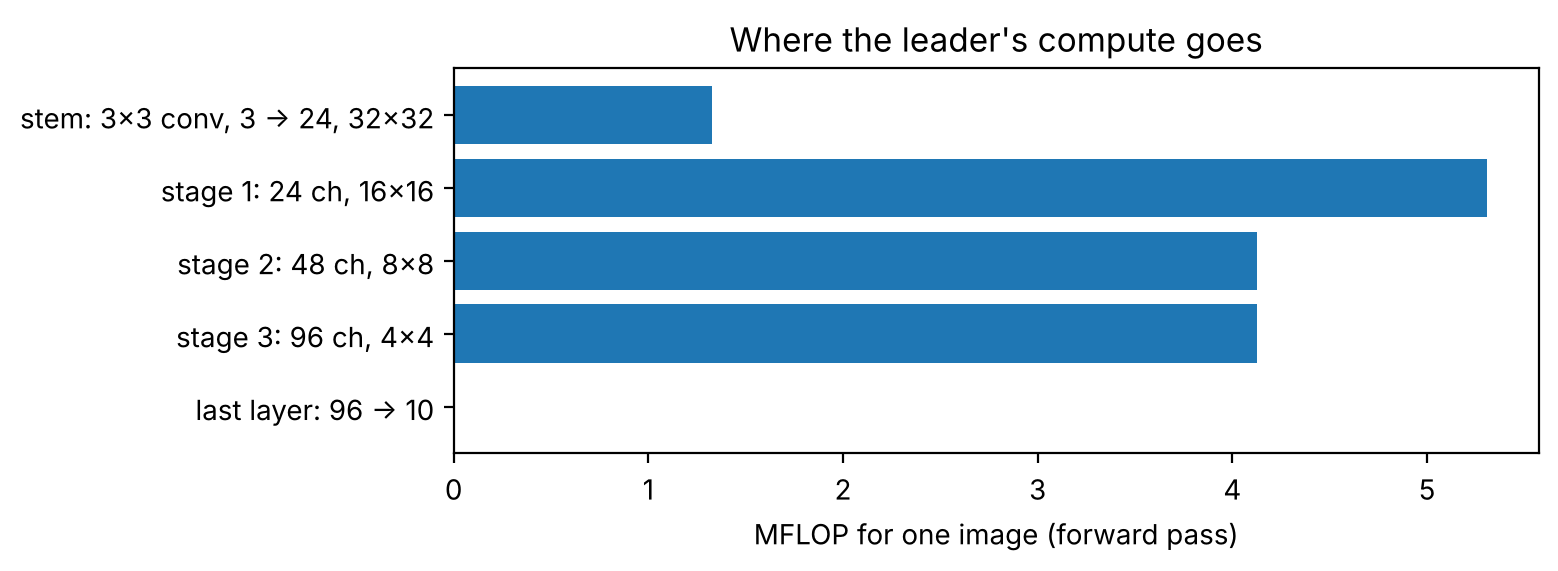

In [3]:
names = [
    "stem: 3x3 conv, 3 -> 24, 32x32",
    "stage 1: 24 ch, 16x16",
    "stage 2: 48 ch, 8x8",
    "stage 3: 96 ch, 4x4",
    "last layer: 96 -> 10",
]
net = model.make_model(leader).eval()
parts = [net[0], net[4], net[5], net[6], net[9]]
x = torch.rand(1, 3, 64, 64)
costs = []
for part in net:
    counter = FlopCounterMode(display=False)
    with counter:
        y = part(x)
    if any(part is p for p in parts):
        costs.append(counter.get_total_flops())
    x = y
total = sum(costs)
for name, cost in zip(names, costs, strict=True):
    print(f"{name:34} {cost / 1e6:6.2f} MFLOP  {100 * cost / total:4.0f}%")
print(f"{'one image, forward':34} {total / 1e6:6.2f} MFLOP")

fig, ax = plt.subplots(figsize=(7, 2.5))
ax.barh(names[::-1], [c / 1e6 for c in costs[::-1]], color="tab:blue")
ax.set_xlabel("MFLOP for one image (forward pass)")
ax.set_title("Where the leader's compute goes")
plt.show()

Three things to notice:

- **The stem is cheap even though it sees the most pixels**, because it has only 3
  colors coming in.
- **Each stage costs about the same.** Halving the image size divides the pixels by 4,
  and doubling the channels multiplies `c_in x c_out` by 4: the two cancel. Stage 1 costs
  a bit more because its 1x1 "shortcut" is not needed there.
- **The last layer is free**: averaging each channel over the image first leaves only
  96 numbers.

## 3 · From one image to all of training

A learning step runs the network forward, then backward. The backward pass works out
two things for each layer, the gradient for its input and the gradient for its weights,
and each costs about as much as the forward pass. So **one step costs about 3 forward
passes** (a bit less: the first layer needs no gradient for the image itself).

In [4]:
per_image_step = lab.step_flops(leader, 64)
print(
    f"one learning step, per image: {per_image_step / 1e6:.2f} MFLOP"
    f" = {per_image_step / total:.2f} x the forward pass"
)

one learning step, per image: 43.36 MFLOP = 2.91 x the forward pass


Training repeats that step for every image in every epoch:

$$\text{training FLOPs} = \text{(cost of one step per image)} \times \text{images} \times \text{epochs}$$

and labelling one test image costs one forward pass per orientation the model looks at:

$$\text{FLOPs per test image} = \text{(forward pass)} \times \text{orientations}$$

In [5]:
train = per_image_step * 21600 * leader.epochs
answer = total * leader.tta
print(
    f"training: {per_image_step / 1e6:.2f} M x 21,600 images x {leader.epochs} epochs"
    f" = {train / 1e12:.2f} TFLOP   (leaderboard: 26.22 TFLOP)"
)
print(
    f"answering: {total / 1e6:.2f} M x {leader.tta} orientations"
    f" = {answer / 1e6:.1f} MFLOP   (leaderboard: 119.2 MFLOP)"
)
print(f"parameters: {lab.parameters(leader):,}   (leaderboard: 174,274)")

training: 43.36 M x 21,600 images x 28 epochs = 26.22 TFLOP   (leaderboard: 26.22 TFLOP)
answering: 14.89 M x 8 orientations = 119.2 MFLOP   (leaderboard: 119.2 MFLOP)
parameters: 174,274   (leaderboard: 174,274)


Our pencil-and-paper model of the leader agrees with the leaderboard to the last digit.
This is worth checking before any experiment: if our harness did not reproduce the
number we want to beat, every comparison after it would be suspect.

## 4 · The budget

A fifth of the leader is **5.2 TFLOP for training** and **24 MFLOP to label one image**.
The two formulas above show the only ways to get there:

| Knob | How the cost changes | What it might cost in accuracy |
|---|---|---|
| fewer epochs | in proportion | less learning |
| fewer orientations at test time | in proportion (answering only) | the leader's 8 views add some accuracy |
| narrower network (channels x m) | about m² | less capacity |
| smaller images inside the network (resolution / 2) | about / 4 | less detail |
| cheaper layer types (for example depthwise convolutions) | depends on the layer | each layer does less |

Here is how far each knob alone would have to go:

In [6]:
for m in (0.5, 0.75, 1.0, 1.5):
    cfg = Config(widths=tuple(round(w * m) for w in (24, 48, 96)))
    step = lab.step_flops(cfg, 64)
    epochs = 5.2e12 / (step * 21600)
    print(
        f"width x {m:<4}: {step / 1e6:5.1f} MFLOP per image-step"
        f" -> {epochs:4.1f} epochs fit in 5.2 TFLOP;"
        f" {step / 3 / 1e6:4.1f} MFLOP per view -> {24e6 / (step / 3):4.1f} views fit in 24 MFLOP"
    )

width x 0.5 :  11.5 MFLOP per image-step -> 20.9 epochs fit in 5.2 TFLOP;  3.8 MFLOP per view ->  6.3 views fit in 24 MFLOP
width x 0.75:  24.9 MFLOP per image-step ->  9.7 epochs fit in 5.2 TFLOP;  8.3 MFLOP per view ->  2.9 views fit in 24 MFLOP
width x 1.0 :  43.4 MFLOP per image-step ->  5.6 epochs fit in 5.2 TFLOP; 14.5 MFLOP per view ->  1.7 views fit in 24 MFLOP
width x 1.5 :  95.6 MFLOP per image-step ->  2.5 epochs fit in 5.2 TFLOP; 31.9 MFLOP per view ->  0.8 views fit in 24 MFLOP


The leader's own network could only train for about 5 epochs (instead of 28) within the
budget, and look at the test image in only 1 or 2 orientations. A network half as wide
costs about a quarter as much: it could train for about 20 epochs and still look in 6
orientations.

So the real question is a trade-off: **for a fixed amount of compute, what is better, a
bigger network trained briefly, or a smaller network trained for longer?** Nothing on
paper answers that: it depends on the data. That is the first experiment in
notebook 2.

## 5 · Compute is not time

The leaderboard counts FLOPs because they are the same on every computer, but the
10-minute limit is about time. Two networks with the same FLOPs can take very different
times: a depthwise convolution does little arithmetic per number it reads, so a
processor spends most of its time fetching memory. We will check the time of the final
model on a 4-core computer like GitHub's before we submit.

## What we take to notebook 2

1. The budget: at most 5.2 TFLOP of training and 24 MFLOP per test image, for 96.3% or
   more.
2. The knobs, with their cost known in advance: epochs, orientations, width, resolution
   and layer type.
3. A harness we trust, because it reproduces the leader's numbers exactly.